In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

filepath = "ev-consumption.csv"
dataset = pd.read_csv(filepath)
dataset.head()

,Trip Energy Consumption,Vehicle ID,Trip Distance,Time of Day,Day of the Week,Longitude,Latitude,Speed,Current,Total Voltage,Maximum Cell Temperature of Battery,Minimum Cell Temperature of Battery,Trip Time Length
0,0.672,1,6,10.333333,4,121.497948,31.281574,246.000000,2.583348,308.283333,31.000000,30.833333,13
1,0.896,1,6,16.000000,4,121.587564,31.256070,393.714286,2.985729,304.485714,29.000000,28.000000,18
2,1.344,1,7,16.090909,2,121.576968,31.262034,192.000000,2.354560,308.463636,31.272727,30.000000,21
3,1.344,1,8,19.000000,5,121.549709,31.257796,369.240000,1.540015,308.060000,30.000000,30.000000,16
4,0.896,1,6,14.166667,6,121.582280,31.215030,413.450617,9.659892,304.473457,28.000000,28.000000,129


[0.672 0.896 1.344 ... 7.84  4.032 1.12 ]
10151
[ 6  6  7 ... 43 18  6]


Text(0, 0.5, 'Energy consumption (kWh)')

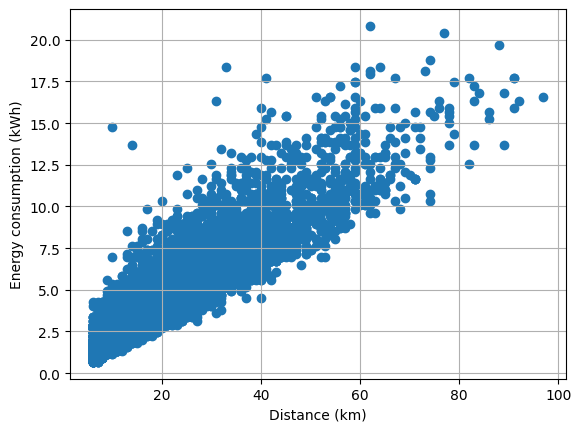

In [13]:
energy_consumption = dataset.iloc[:,0].values # energy consumption in kWh
print(energy_consumption)
print(len(energy_consumption))
trip_distance = dataset.iloc[:,2].values # distance in kilometers
print(trip_distance)

plt.scatter(trip_distance, energy_consumption)
plt.grid(True)
plt.xlabel("Distance (km)")
plt.ylabel("Energy consumption (kWh)")

[246.         393.7142857  192.         ...  23.5625      19.27659574
   2.57142857]


Text(0.5, 0, 'Energy consumption (kWh)')

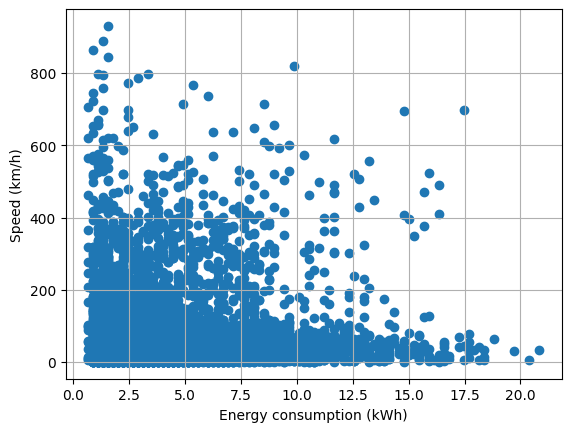

In [17]:
speed = dataset.iloc[:,7].values # average speed during trip in km/h
print(speed)

plt.scatter(energy_consumption, speed)
plt.grid(True)
plt.ylabel("Speed (km/h)")
plt.xlabel("Energy consumption (kWh)")

[13 18 21 ... 65 84 53]


Text(0, 0.5, 'Energy consumption (kWh)')

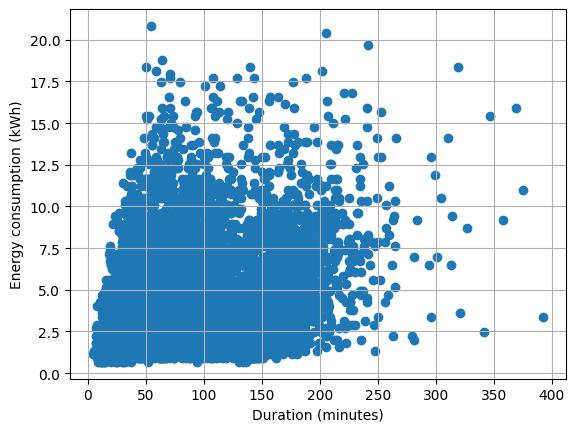

In [18]:
duration = dataset.iloc[:,-1].values # duration of trip in minutes
print(duration)

plt.scatter(duration, energy_consumption)
plt.grid(True)
plt.xlabel("Duration (minutes)")
plt.ylabel("Energy consumption (kWh)")

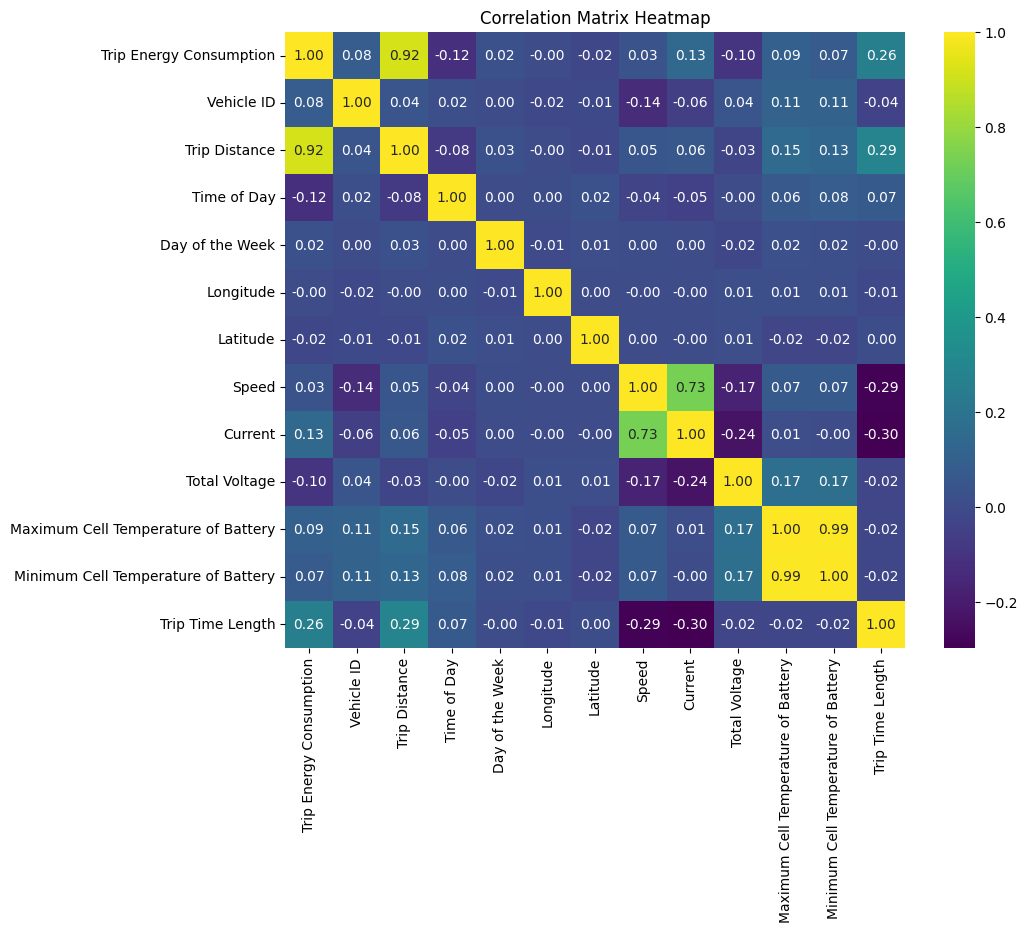

In [22]:
import seaborn as sns

correlation_matrix = dataset.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='viridis', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

[121.4979483 121.5875639 121.5769682 ... 121.4113328 121.4671568
 121.4466122]
[31.28157417 31.25606986 31.26203436 ... 31.0531279  30.85428936
 30.90318776]


Text(0, 0.5, 'Latitude')

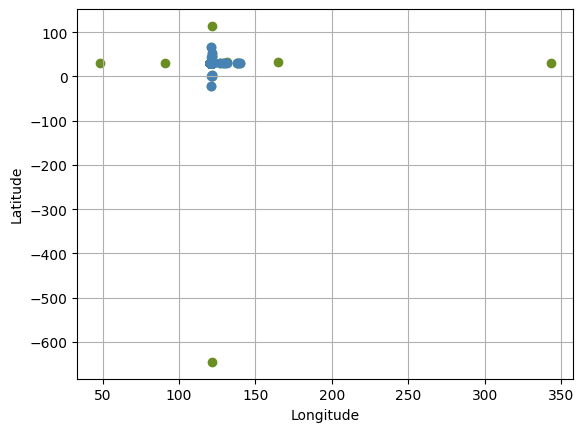

In [31]:
longitude = dataset.iloc[:,5].values
latitude = dataset.iloc[:,6].values
longitude_filtered = longitude[(longitude < 150) & (longitude > 100)]
latitude_filtered = latitude[(latitude < 100) & (latitude > -100)]
min_length = min(len(longitude_filtered), len(latitude_filtered))
longitude_filtered = longitude_filtered[:min_length]
latitude_filtered = latitude_filtered[:min_length]
print(longitude)
print(latitude)

# shanghai is flat

plt.scatter(longitude, latitude, c="olivedrab")
plt.scatter(longitude_filtered, latitude_filtered, c="steelblue")
plt.grid(True)
plt.xlabel("Longitude")
plt.ylabel("Latitude")

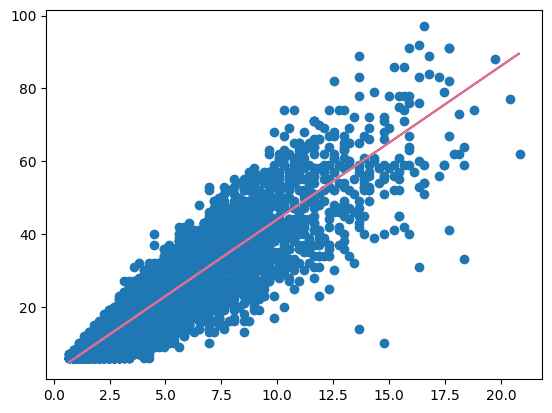

Slope = 4.214918680284201 km/kWh
kWh/km = 0.23725250137745776
kWh/mi = 0.38182100770306


In [40]:
# linear approximation b/w speed and energy consumption
slope, intercept = np.polyfit(energy_consumption, trip_distance, 1)

def linear_approx(x):
  return slope * x + intercept

pred = linear_approx(energy_consumption)
plt.scatter(energy_consumption, trip_distance)
plt.plot(energy_consumption, pred, color = "palevioletred")
plt.show()

print(f"Slope = {slope} km/kWh")
inverse_slope = 1 / slope
print(f"kWh/km = {inverse_slope}")

mi_slope, intercept = np.polyfit(energy_consumption, trip_distance*0.621371, 1)
mi_slope = 1 / mi_slope
print(f"kWh/mi = {mi_slope}")